# Experiment 4: R Project Implementation and Version Control Using GitHub

**Name:** Sheshank Singh  
**Roll Number:** 23102A0017  
**Subject:** R Programming

## 1. Problem Statement
The lab requires studying the prescribed video, implementing its project in R, testing the results, organizing source code and outputs, and publishing the work with Git and GitHub.

## 2. Objectives
- Inspect and prepare a dataset in R.
- Perform exploratory analysis and visualization.
- Fit and evaluate a basic predictive model.
- Validate outputs and save project artifacts.
- Document the project and outline Git/GitHub version control steps.

## 3. Project and Dataset
**Example project:** Explore vehicle characteristics and estimate fuel economy (`mpg`) using the `mtcars` dataset bundled with R. It contains 32 observations and 11 variables from 1974 Motor Trend car road tests.

Variables used include `mpg` (miles per US gallon), `cyl` (cylinders), `disp` (displacement), `hp` (horsepower), `wt` (weight) and `am` (transmission: 0 automatic, 1 manual). No external download is needed for this example.

## 4. Install and Load Packages

Base R handles the data and model; `ggplot2` is used for visualization.

In [1]:
if (!requireNamespace("ggplot2", quietly = TRUE)) {
  install.packages("ggplot2", repos = "https://cloud.r-project.org")
}
library(ggplot2)
cat("R version:", R.version.string, "\n")
cat("ggplot2 version:", as.character(packageVersion("ggplot2")), "\n")

R version: R version 4.6.1 (2026-06-24) 
ggplot2 version: 4.0.3 


## 5. Load and Inspect Data

In [2]:
data("mtcars")
vehicle_data <- mtcars
vehicle_data$car_name <- rownames(vehicle_data)
rownames(vehicle_data) <- NULL

cat("Rows:", nrow(vehicle_data), "\n")
cat("Columns:", ncol(vehicle_data), "\n")
str(vehicle_data)
head(vehicle_data)

Rows: 32 
Columns: 12 
'data.frame':	32 obs. of  12 variables:
 $ mpg     : num  21 21 22.8 21.4 18.7 18.1 14.3 24.4 22.8 19.2 ...
 $ cyl     : num  6 6 4 6 8 6 8 4 4 6 ...
 $ disp    : num  160 160 108 258 360 ...
 $ hp      : num  110 110 93 110 175 105 245 62 95 123 ...
 $ drat    : num  3.9 3.9 3.85 3.08 3.15 2.76 3.21 3.69 3.92 3.92 ...
 $ wt      : num  2.62 2.88 2.32 3.21 3.44 ...
 $ qsec    : num  16.5 17 18.6 19.4 17 ...
 $ vs      : num  0 0 1 1 0 1 0 1 1 1 ...
 $ am      : num  1 1 1 0 0 0 0 0 0 0 ...
 $ gear    : num  4 4 4 3 3 3 3 4 4 4 ...
 $ carb    : num  4 4 1 1 2 1 4 2 2 4 ...
 $ car_name: chr  "Mazda RX4" "Mazda RX4 Wag" "Datsun 710" "Hornet 4 Drive" ...


,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb,car_name
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,21.0,6,160,110,3.90,2.620,16.46,0,1,4,4,Mazda RX4
2,21.0,6,160,110,3.90,2.875,17.02,0,1,4,4,Mazda RX4 Wag
3,22.8,4,108,93,3.85,2.320,18.61,1,1,4,1,Datsun 710
4,21.4,6,258,110,3.08,3.215,19.44,1,0,3,1,Hornet 4 Drive
5,18.7,8,360,175,3.15,3.440,17.02,0,0,3,2,Hornet Sportabout
6,18.1,6,225,105,2.76,3.460,20.22,1,0,3,1,Valiant


In [3]:
summary(vehicle_data)

      mpg             cyl             disp             hp       
 Min.   :10.40   Min.   :4.000   Min.   : 71.1   Min.   : 52.0  
 1st Qu.:15.43   1st Qu.:4.000   1st Qu.:120.8   1st Qu.: 96.5  
 Median :19.20   Median :6.000   Median :196.3   Median :123.0  
 Mean   :20.09   Mean   :6.188   Mean   :230.7   Mean   :146.7  
 3rd Qu.:22.80   3rd Qu.:8.000   3rd Qu.:326.0   3rd Qu.:180.0  
 Max.   :33.90   Max.   :8.000   Max.   :472.0   Max.   :335.0  
      drat             wt             qsec             vs        
 Min.   :2.760   Min.   :1.513   Min.   :14.50   Min.   :0.0000  
 1st Qu.:3.080   1st Qu.:2.581   1st Qu.:16.89   1st Qu.:0.0000  
 Median :3.695   Median :3.325   Median :17.71   Median :0.0000  
 Mean   :3.597   Mean   :3.217   Mean   :17.85   Mean   :0.4375  
 3rd Qu.:3.920   3rd Qu.:3.610   3rd Qu.:18.90   3rd Qu.:1.0000  
 Max.   :4.930   Max.   :5.424   Max.   :22.90   Max.   :1.0000  
       am              gear            carb            car_name 
 Min.   :0.0000   

In [4]:
missing_summary <- data.frame(
  Variable = names(vehicle_data),
  Missing_Values = vapply(vehicle_data, function(x) sum(is.na(x)), integer(1))
)
missing_summary

,Variable,Missing_Values
,<chr>,<int>
mpg,mpg,0
cyl,cyl,0
disp,disp,0
hp,hp,0
drat,drat,0
wt,wt,0
qsec,qsec,0
vs,vs,0
am,am,0


## 6. Data Cleaning and Feature Preparation

The built-in dataset is already structured. This section checks duplicate records, validates key numeric values and adds readable transmission labels.

In [5]:
rows_before <- nrow(vehicle_data)
vehicle_data <- vehicle_data[!duplicated(vehicle_data), ]
vehicle_data <- subset(vehicle_data, mpg > 0 & wt > 0 & hp >= 0 & cyl > 0)
vehicle_data$transmission <- factor(
  vehicle_data$am, levels = c(0, 1),
  labels = c("Automatic", "Manual")
)
cat("Rows before cleaning:", rows_before, "\n")
cat("Rows after cleaning:", nrow(vehicle_data), "\n")
cat("Rows removed:", rows_before - nrow(vehicle_data), "\n")
head(vehicle_data)

Rows before cleaning: 32 
Rows after cleaning: 32 
Rows removed: 0 


,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb,car_name,transmission
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<fct>
1,21.0,6,160,110,3.90,2.620,16.46,0,1,4,4,Mazda RX4,Manual
2,21.0,6,160,110,3.90,2.875,17.02,0,1,4,4,Mazda RX4 Wag,Manual
3,22.8,4,108,93,3.85,2.320,18.61,1,1,4,1,Datsun 710,Manual
4,21.4,6,258,110,3.08,3.215,19.44,1,0,3,1,Hornet 4 Drive,Automatic
5,18.7,8,360,175,3.15,3.440,17.02,0,0,3,2,Hornet Sportabout,Automatic
6,18.1,6,225,105,2.76,3.460,20.22,1,0,3,1,Valiant,Automatic


## 7. Exploratory Data Analysis

In [6]:
fuel_summary <- aggregate(
  mpg ~ transmission, data = vehicle_data,
  FUN = function(x) c(Count = length(x), Mean = mean(x), Median = median(x), SD = sd(x))
)
fuel_summary

transmission,mpg
<fct>,"<dbl[,4]>"
Automatic,"19, 17.14737, 17.3, 3.833966"
Manual,"13, 24.39231, 22.8, 6.166504"


In [7]:
correlation_matrix <- cor(
  vehicle_data[, c("mpg", "cyl", "disp", "hp", "wt")],
  use = "complete.obs"
)
round(correlation_matrix, 3)

,mpg,cyl,disp,hp,wt
mpg,1.000,-0.852,-0.848,-0.776,-0.868
cyl,-0.852,1.000,0.902,0.832,0.782
disp,-0.848,0.902,1.000,0.791,0.888
hp,-0.776,0.832,0.791,1.000,0.659
wt,-0.868,0.782,0.888,0.659,1.000


## 8. Visualizations

`geom_smooth()` using formula = 'y ~ x'


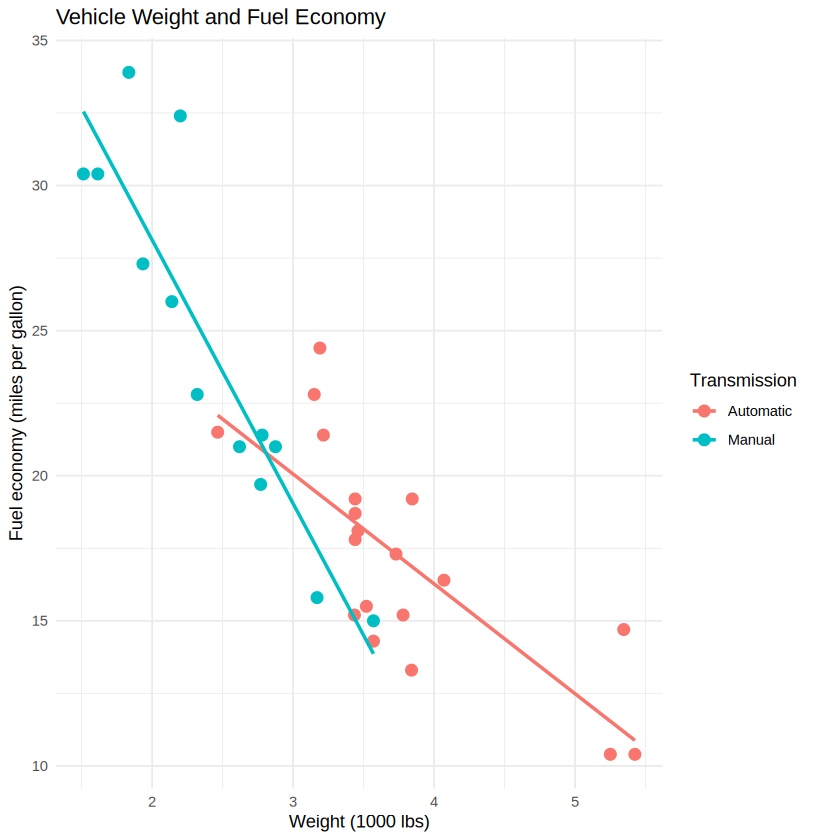

In [8]:
ggplot(vehicle_data, aes(x = wt, y = mpg, color = transmission)) +
  geom_point(size = 3) +
  geom_smooth(method = "lm", se = FALSE) +
  labs(title = "Vehicle Weight and Fuel Economy",
       x = "Weight (1000 lbs)", y = "Fuel economy (miles per gallon)",
       color = "Transmission") +
  theme_minimal()

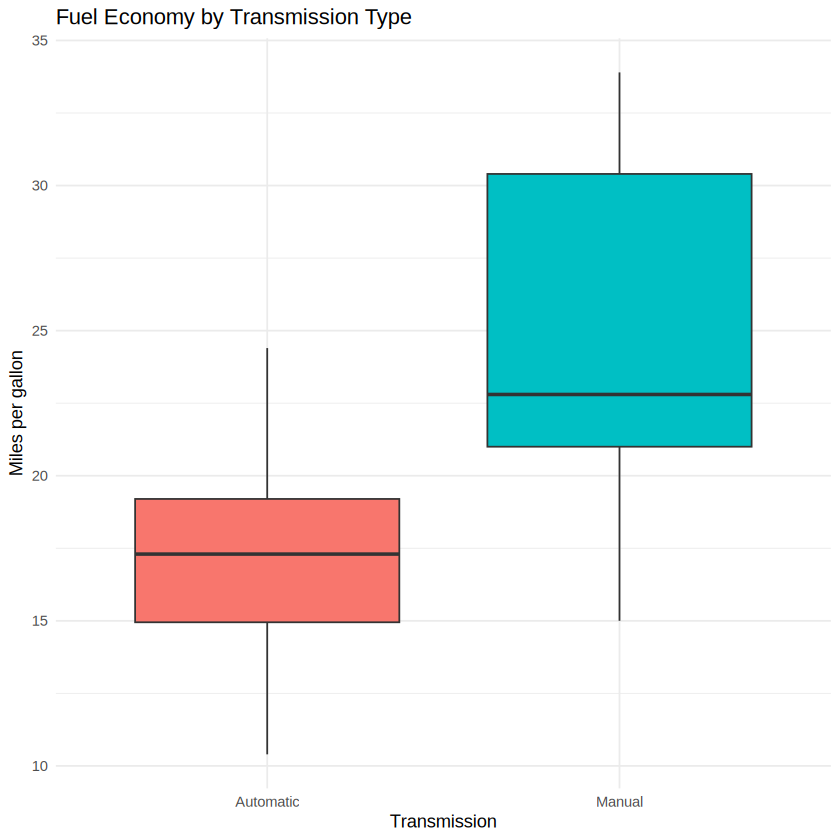

In [9]:
ggplot(vehicle_data, aes(x = transmission, y = mpg, fill = transmission)) +
  geom_boxplot() +
  labs(title = "Fuel Economy by Transmission Type",
       x = "Transmission", y = "Miles per gallon") +
  theme_minimal() + guides(fill = "none")

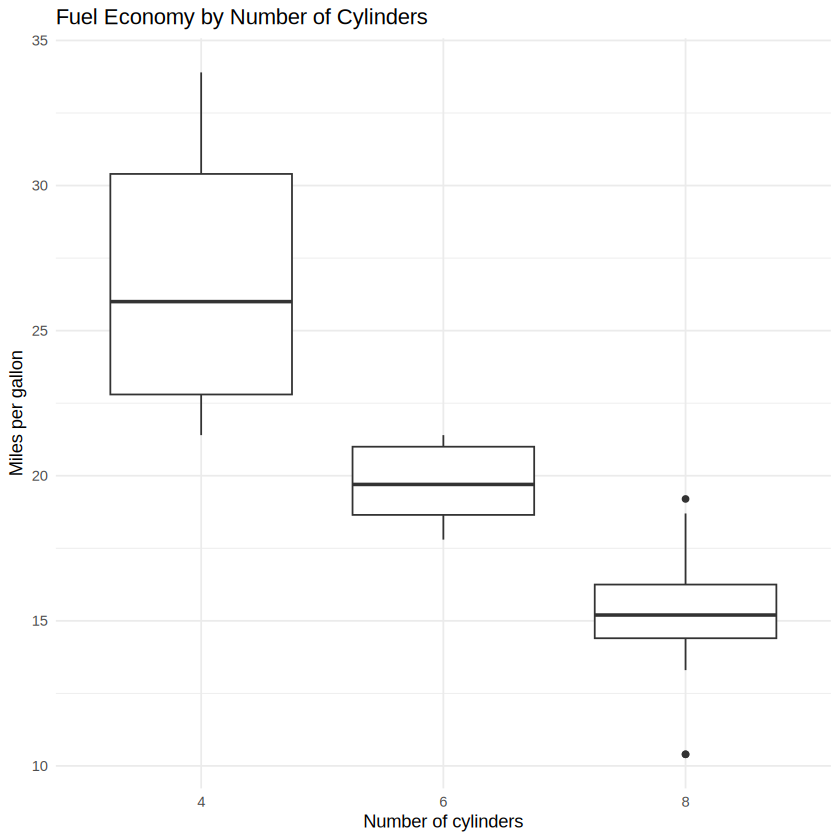

In [10]:
ggplot(vehicle_data, aes(x = factor(cyl), y = mpg)) +
  geom_boxplot() +
  labs(title = "Fuel Economy by Number of Cylinders",
       x = "Number of cylinders", y = "Miles per gallon") +
  theme_minimal()

## 9. Predictive Analysis Using Linear Regression

A multiple linear regression model estimates `mpg` from vehicle weight, horsepower, displacement and cylinder count.

In [11]:
model <- lm(mpg ~ wt + hp + disp + cyl, data = vehicle_data)
summary(model)


Call:
lm(formula = mpg ~ wt + hp + disp + cyl, data = vehicle_data)

Residuals:
    Min      1Q  Median      3Q     Max 
-4.0562 -1.4636 -0.4281  1.2854  5.8269 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept) 40.82854    2.75747  14.807 1.76e-14 ***
wt          -3.85390    1.01547  -3.795 0.000759 ***
hp          -0.02054    0.01215  -1.691 0.102379    
disp         0.01160    0.01173   0.989 0.331386    
cyl         -1.29332    0.65588  -1.972 0.058947 .  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 2.513 on 27 degrees of freedom
Multiple R-squared:  0.8486,	Adjusted R-squared:  0.8262 
F-statistic: 37.84 on 4 and 27 DF,  p-value: 1.061e-10


In [12]:
vehicle_data$predicted_mpg <- predict(model, newdata = vehicle_data)
vehicle_data$residual <- vehicle_data$mpg - vehicle_data$predicted_mpg
head(vehicle_data[, c("car_name", "mpg", "predicted_mpg", "residual")])

,car_name,mpg,predicted_mpg,residual
,<chr>,<dbl>,<dbl>,<dbl>
1,Mazda RX4,21.0,22.56805,-1.56804806
2,Mazda RX4 Wag,21.0,21.58530,-0.58530266
3,Datsun 710,22.8,26.05685,-3.25685052
4,Hornet 4 Drive,21.4,21.41170,-0.01170091
5,Hornet Sportabout,18.7,17.80606,0.89393888
6,Valiant,18.1,20.18741,-2.08741154


In [13]:
actual <- vehicle_data$mpg
predicted <- vehicle_data$predicted_mpg
regression_metrics <- data.frame(
  Metric = c("RMSE", "MAE", "R-squared"),
  Value = c(
    sqrt(mean((actual - predicted)^2)),
    mean(abs(actual - predicted)),
    summary(model)$r.squared
  )
)
regression_metrics

Metric,Value
<chr>,<dbl>
RMSE,2.3078965
MAE,1.7709519
R-squared,0.8486348


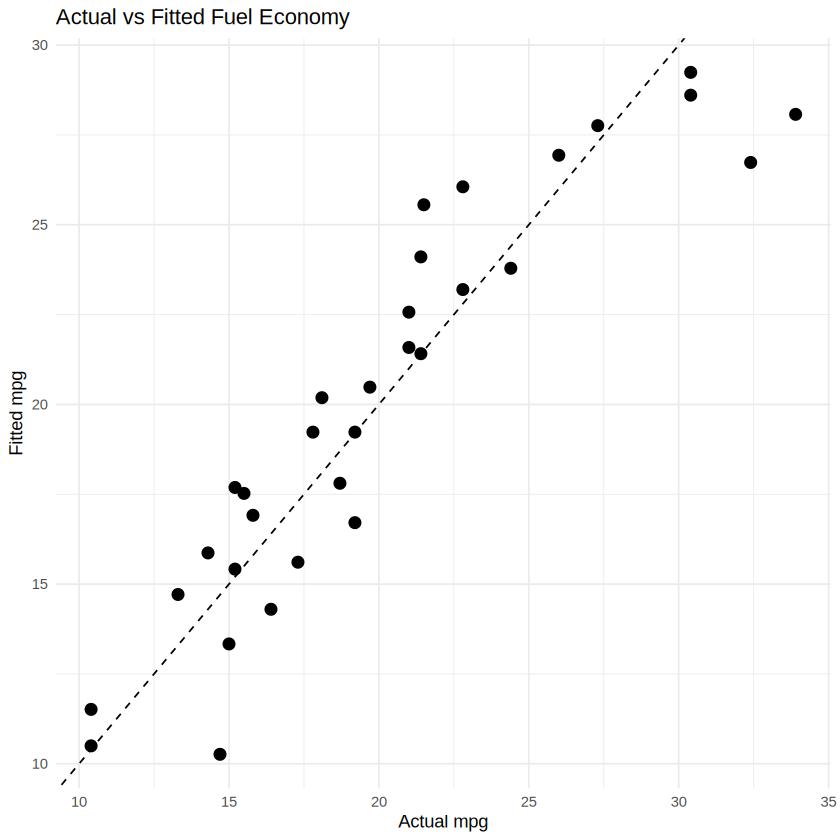

In [14]:
ggplot(vehicle_data, aes(x = mpg, y = predicted_mpg)) +
  geom_point(size = 3) +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed") +
  labs(title = "Actual vs Fitted Fuel Economy",
       x = "Actual mpg", y = "Fitted mpg") +
  theme_minimal()

## 10. Validate Results

In [ ]:
stopifnot(nrow(vehicle_data) > 0)
stopifnot(inherits(model, "lm"))
stopifnot(all(is.finite(vehicle_data$predicted_mpg)))
stopifnot(all(is.finite(regression_metrics$Value)))
cat("Validation passed: dataset and model outputs are available.\n")

## 11. Save Project Outputs

Files are saved in the current runtime. Download them or copy them into the local project folder before pushing to GitHub.

In [15]:
if (!dir.exists("outputs")) dir.create("outputs", recursive = TRUE)
write.csv(vehicle_data, "outputs/vehicle_analysis_data.csv", row.names = FALSE)
write.csv(regression_metrics, "outputs/regression_metrics.csv", row.names = FALSE)
capture.output(summary(model), file = "outputs/model_summary.txt")
list.files("outputs")

[1] "model_summary.txt"         "regression_metrics.csv"   
[3] "vehicle_analysis_data.csv"

## 12. Recommended Project Structure

```text
Lab-Problem-04-R-Project/
├── README.md
├── Lab_Problem_04_R_Project_GitHub.ipynb
├── outputs/
   ├── vehicle_analysis_data.csv
   ├── regression_metrics.csv
   └── model_summary.txt
```

Because this example uses a built-in dataset, no separate raw data file is needed. If the prescribed video uses an external dataset, add its file or a reliable source link, respecting its license and size.

## 16. Results and Interpretation

After running the notebook, report the retained record count, fuel-economy differences between transmission types, relationships among selected variables, model coefficients, R-squared, RMSE and MAE.

The regression metrics here are calculated on the same data used to fit the model. They measure in-sample fit and should not be described as independent test-set performance.

## 17. Conclusion

This experiment demonstrates an end-to-end R project workflow, including data inspection, cleaning, exploratory analysis, visualization, regression, validation, output generation and documentation. Git and GitHub provide a way to track changes and share the work.